# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

### Службова клітинка: таймер виконання

Ця клітинка потрібна для відповіді на питання про тривалість виконання: вона підключає до IPython обробник, який після кожної клітинки записує, скільки секунд вона виконувалася. Запускайте її **першою**.

In [1]:
import json
import os
import time

from IPython import get_ipython

TIMES_FILE = "cell_times_01.json"  # файл переживе перезапуск середовища в межах сесії Colab
CELL_TIMES = json.load(open(TIMES_FILE)) if os.path.exists(TIMES_FILE) else []
_started = [None]


def _pre_run(*args):
    _started[0] = time.perf_counter()


def _post_run(result=None):
    if _started[0] is None:  # саму службову клітинку не вимірюємо
        return
    raw = (getattr(getattr(result, "info", None), "raw_cell", "") or "").strip()
    CELL_TIMES.append({
        "cell": getattr(result, "execution_count", None),
        "sec": round(time.perf_counter() - _started[0], 1),
        "code": raw.splitlines()[0][:70] if raw else "",
    })
    with open(TIMES_FILE, "w") as f:
        json.dump(CELL_TIMES, f)


ip = get_ipython()
for event, callback in (("pre_run_cell", _pre_run), ("post_run_cell", _post_run)):
    for old in list(ip.events.callbacks[event]):
        if getattr(old, "__name__", "") == callback.__name__:
            ip.events.unregister(event, old)
    ip.events.register(event, callback)
print("Таймер клітинок увімкнено")

Таймер клітинок увімкнено


In [2]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [3]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [4]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:01<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [5]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [6]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [7]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [8]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [9]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [11]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [12]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [13]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [14]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



### Додаткові перевірки на власних прикладах (питання 10)

Додаємо ще **4 власні перевірки** до трьох початкових. Кожна перевіряє окреме явище, на якому парафразу легко помилитися:
1. **парафраза зі зміною порядку слів і активу на пасив** — речення звучать по-різному, а зміст той самий (очікуємо «парафраз»);
2. **ті самі слова, але ролі міняються місцями** («собака вкусила чоловіка» і «чоловік вкусив собаку») — майже повний збіг слів, а зміст різний (очікуємо «не парафраз»);
3. **заперечення** — одне слово `not` повністю змінює зміст (очікуємо «не парафраз»);
4. **інше число** — 500 проти 5 000 працівників: змінився факт (очікуємо «не парафраз»).

Мітки 1 (парафраз) і 0 (не парафраз) задано нами вручну, це еталон для порівняння.

In [15]:
def paraphrase_probability(model, sentence1, sentence2):
    """Ймовірність класу «парафраз» (мітка 1), яку дає модель."""
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        return model(**inputs).logits.softmax(dim=-1)[0, 1].item()


# (речення 1, речення 2, еталонна мітка, яке явище перевіряємо)
extra_pairs = [
    ("The committee approved the new budget on Monday.",
     "On Monday, the new budget was approved by the committee.", 1, "інший порядок слів, пасив"),
    ("The dog bit the man.", "The man bit the dog.", 0, "ті самі слова, ролі навпаки"),
    ("The doctor said the patient will recover soon.",
     "The doctor said the patient will not recover soon.", 0, "заперечення"),
    ("The company has 500 employees in Kyiv.", "The company has 5,000 employees in Kyiv.", 0, "інше число"),
]

correct = 0
for s1, s2, gold, phenomenon in extra_pairs:
    prob = paraphrase_probability(model, s1, s2)
    predicted = int(prob > 0.5)
    correct += predicted == gold
    mark = "✓" if predicted == gold else "✗"
    print(f"{mark} [{phenomenon}]\n  {s1}\n  {s2}\n  P(парафраз) = {prob:.1%}; "
          f"модель: {'парафраз' if predicted else 'не парафраз'}; еталон: {'парафраз' if gold else 'не парафраз'}\n")
print(f"Правильно: {correct} із {len(extra_pairs)}")

✓ [інший порядок слів, пасив]
  The committee approved the new budget on Monday.
  On Monday, the new budget was approved by the committee.
  P(парафраз) = 99.3%; модель: парафраз; еталон: парафраз

✗ [ті самі слова, ролі навпаки]
  The dog bit the man.
  The man bit the dog.
  P(парафраз) = 98.1%; модель: парафраз; еталон: не парафраз

✗ [заперечення]
  The doctor said the patient will recover soon.
  The doctor said the patient will not recover soon.
  P(парафраз) = 99.2%; модель: парафраз; еталон: не парафраз

✗ [інше число]
  The company has 500 employees in Kyiv.
  The company has 5,000 employees in Kyiv.
  P(парафраз) = 97.4%; модель: парафраз; еталон: не парафраз

Правильно: 1 із 4


## Відповіді на теоретичні питання (0.1)

Питання 1–10 до цього ноутбука. До кожної відповіді додано код, який її підтверджує. Усі клітинки нижче потрібно запускати **після** основної частини ноутбука (вони використовують змінні `model`, `trainer`, `tokenizer`, `tokenized_datasets`, створені вище).

### Питання 1. Як довго виконувалися клітинки ноутбуку 01_bert_head? Чи були проблеми з запуском, які?

**Відповідь.** Час виконання вимірювала службова клітинка на початку ноутбука: вона записує тривалість кожної клітинки. Таблицю підсумків виведено клітинкою нижче.

**Скільки це тривало** (безкоштовний Colab, GPU Tesla T4):
- за таймером, на момент цієї таблиці виконано 14 клітинок, разом **2,6 хв**. Найдовші: повне донавчання BERT на 3 епохи — 79,7 с (прогрес-бар `Trainer` показав 1 хв 16 с на 690 кроків); перший імпорт `numpy`/`torch`/`transformers` — 51,9 с; завантаження `pipeline('fill-mask')` разом із вагами `bert-base-uncased` (440 MB) — 12,2 с; завантаження датасету MRPC — 7,3 с;
- клітинки з відповідями на питання 2–10 додали ще приблизно 5 хв. Майже весь цей час — два тренування: «лише голова» на 3 епохи (28 с за прогрес-баром `Trainer`) і 10 епох для питання 9 (4 хв 3 с); решта клітинок виконується за секунди.

Разом ноутбук виконується приблизно за **8 хв** (2,6 хв — за таймером; тривалості пізніших тренувань взято з прогрес-барів `Trainer`, бо таблиця таймера виведена раніше за ці клітинки).

**Проблеми з запуском.**
1. Єдина помилка виконання — `KeyError: 'eval_train_loss'` у клітинці з таблицею по епохах (питання 9). Причина: коли в `Trainer` передано *словник* `eval_dataset`, метрики кожного набору записуються в `log_history` окремими записами, тож поля `eval_train_*` і `eval_validation_*` не лежать в одному записі. Виправлено злиттям записів за номером кроку; повторювати навчання не довелося.
2. Попередження, які не є помилками: `You are sending unauthenticated requests to the HF Hub` — завантаження без токена Hugging Face (працює, але з нижчим лімітом запитів); `LOAD REPORT` зі статусами `UNEXPECTED` і `MISSING` — очікувана поведінка: ваги `classifier.*` відсутні в чекпойнті й ініціалізуються випадково (нова голова), а ваги голів MLM/NSP (`cls.*`), непотрібні для класифікації, відкидаються.
3. Потрібна GPU: ноутбук перевіряє її наявність на початку (`Tesla T4`).

In [16]:
import pandas as pd


def timing_report(top=6):
    """Скільки часу забрали клітинки ноутбука (за даними службової клітинки з початку ноутбука)."""
    times = pd.DataFrame(CELL_TIMES)
    print(f"Виконано клітинок: {len(times)}; сумарний час їх виконання: {times['sec'].sum() / 60:.1f} хв")
    print(f"Найдовші {top} клітинок:")
    return times.sort_values("sec", ascending=False).head(top)[["cell", "sec", "code"]].reset_index(drop=True)


timing_report()

Виконано клітинок: 14; сумарний час їх виконання: 2.6 хв
Найдовші 6 клітинок:


,cell,sec,code
0,13,79.7,"print(f""Параметрів, що тренуються: {count_para..."
1,2,51.9,import numpy as np
2,6,12.2,from transformers import pipeline
3,4,7.3,"raw_datasets = load_dataset(""nyu-mll/glue"", ""m..."
4,9,3.7,def tokenize_function(batch):
5,8,0.7,"checkpoint = ""bert-base-uncased"""


### Питання 2. Як Ви розумієте, що таке токен [CLS]? Яким чином він виконує свою функцію?

**Відповідь.** `[CLS]` (від *classification*) — службовий токен, який BERT завжди ставить **на початок** послідовності. Це не слово тексту й не має власного змісту: він слугує «порожнім слотом», у якому модель накопичує підсумкове представлення всього входу — і першого, і другого речення.

Як він виконує свою функцію:
1. **Під час попереднього тренування.** До вектора `[CLS]` на виході останнього шару підʼєднано задачу NSP (чи йде речення B за реченням A). Щоб її розвʼязати, модель навчилася збирати в цей вектор інформацію про обидва речення.
2. **Через self-attention.** У кожному з 12 шарів `[CLS]` може «дивитися» на всі токени обох речень (BERT двонаправлений), тому після останнього шару його вектор залежить від усієї послідовності, а не від одного слова.
3. **Під час класифікації** саме цей вектор (768 чисел) іде в голову: `BertForSequenceClassification` пропускає його через pooler (лінійний шар + tanh), dropout і лінійний шар-класифікатор, який дає 2 логіти.
4. **Під час донавчання** градієнт функції втрат іде з голови назад у вектор `[CLS]` і далі в усі шари, тому модель підлаштовує, яку саме інформацію збирати в цьому слоті для нашої задачі (парафраза чи ні).

Код нижче показує, що (а) `[CLS]` справді стоїть на позиції 0, (б) його вектор має розмір 768 і (в) **змінюється, коли змінюється друге речення**, тобто несе інформацію про всю пару.

**Результат запуску.** Для обох пар на позиції 0 стоїть токен `[CLS]` (id 101); кістяк повертає тензори форми (1, 22, 768) і (1, 20, 768), тобто вектор із 768 чисел на кожен токен. Модель оцінила пару A (парафраза) як парафразу з імовірністю 86,0%, а пару B (різні за змістом речення) — 2,6%. Вектори `[CLS]` цих двох пар відрізняються вже першими компонентами, а косинусна подібність між ними вийшла ≈ 0,000: тобто `[CLS]` не є однаковою константою, його вміст залежить від другого речення.

In [17]:
from torch.nn.functional import cosine_similarity

pair_a = ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit.")
pair_b = ("The company reported a profit of $5 million.", "The weather was sunny all week.")

model.eval()
cls_vectors = []
for s1, s2 in (pair_a, pair_b):
    enc = tokenizer(s1, s2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        hidden = model.bert(**enc).last_hidden_state  # форма [1, довжина, 768]: вектор для кожного токена
        probs = model(**enc).logits.softmax(-1)[0]
    cls_vectors.append(hidden[0, 0])  # вектор токена на позиції 0, тобто [CLS]
    first_id = int(enc["input_ids"][0, 0])
    print(f"Позиція 0: {tokenizer.convert_ids_to_tokens(first_id)!r} (id {first_id}); "
          f"форма виходу кістяка: {tuple(hidden.shape)}; P(парафраз) = {probs[1]:.1%}")

similarity = cosine_similarity(cls_vectors[0], cls_vectors[1], dim=0).item()
print(f"\nПерші 5 чисел CLS-вектора пари A: {[round(v, 3) for v in cls_vectors[0][:5].tolist()]}")
print(f"Перші 5 чисел CLS-вектора пари B: {[round(v, 3) for v in cls_vectors[1][:5].tolist()]}")
print(f"Косинусна подібність CLS-векторів пар A і B: {similarity:.3f} (1.0 означало б однакові вектори)")
print("\npooler, через який вектор [CLS] потрапляє в голову:")
print(model.bert.pooler)

Позиція 0: '[CLS]' (id 101); форма виходу кістяка: (1, 22, 768); P(парафраз) = 86.0%
Позиція 0: '[CLS]' (id 101); форма виходу кістяка: (1, 20, 768); P(парафраз) = 2.6%

Перші 5 чисел CLS-вектора пари A: [-1.296, 0.46, 0.322, 0.349, -0.635]
Перші 5 чисел CLS-вектора пари B: [-0.032, -0.282, 0.526, 0.215, 0.662]
Косинусна подібність CLS-векторів пар A і B: 0.000 (1.0 означало б однакові вектори)

pooler, через який вектор [CLS] потрапляє в голову:
BertPooler(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (activation): Tanh()
)


### Питання 3. Яке пряме застосування базової моделі bert-base-uncased?

**Відповідь.** «Прямо», без донавчання, `bert-base-uncased` можна використовувати лише для тих двох задач, на яких її попередньо тренували (див. [картку моделі](https://huggingface.co/google-bert/bert-base-uncased)):
- **MLM (masked language modeling)** — передбачення замаскованого слова в англійському реченні (`fill-mask`, як у цьому ноутбуці);
- **NSP (next sentence prediction)** — оцінка, чи йде друге речення за першим.

Генерувати текст BERT не вміє: це двонаправлений енкодер, а для генерації потрібні авторегресійні моделі (GPT, Qwen тощо). Тому головне призначення базового BERT — бути **кістяком для донавчання** під задачі, що працюють з цілими реченнями (класифікація, розпізнавання сутностей, питання-відповідь), і джерелом контекстних векторів-представлень — саме так він використаний у цьому демо.

Код нижче перевіряє обидва прямі застосування.

**Результат запуску.** MLM: у реченні «Paris is the [MASK] of France.» модель ставить `capital` з імовірністю 99,7%; у «He opened the [MASK] and started typing.» — `laptop` (20,7%), `door` (10,2%), `browser` (9,4%): слово добирається за контекстом. NSP: для пари «The man went to the store.» + «He bought a gallon of milk.» імовірність продовження 100,0%, а для «The man went to the store.» + «Penguins live in Antarctica.» — 0,0%.

In [18]:
from transformers import BertForNextSentencePrediction

# 1) MLM: заповнюємо пропущене слово
for sentence in ("Paris is the [MASK] of France.", "He opened the [MASK] and started typing."):
    top = unmasker(sentence, top_k=3)
    print(sentence, "→", [(t["token_str"], round(t["score"], 3)) for t in top])

# 2) NSP: чи є друге речення продовженням першого (клас 0 — «так», клас 1 — «випадкове речення»)
nsp_model = BertForNextSentencePrediction.from_pretrained(checkpoint).to(device).eval()
nsp_tests = [
    ("The man went to the store.", "He bought a gallon of milk."),
    ("The man went to the store.", "Penguins live in Antarctica."),
]
print()
for first, second in nsp_tests:
    enc = tokenizer(first, second, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = nsp_model(**enc).logits.softmax(-1)[0]
    print(f"{first} | {second}\n  P(друге речення — продовження) = {probs[0]:.1%}")
del nsp_model

Paris is the [MASK] of France. → [('capital', 0.997), ('heart', 0.001), ('center', 0.0)]
He opened the [MASK] and started typing. → [('laptop', 0.207), ('door', 0.102), ('browser', 0.094)]


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForNextSentencePrediction LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



The man went to the store. | He bought a gallon of milk.
  P(друге речення — продовження) = 100.0%
The man went to the store. | Penguins live in Antarctica.
  P(друге речення — продовження) = 0.0%


### Питання 4. Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?

**Відповідь.** Так, варто. Приклад вище (`man` → carpenter, waiter, mechanic; `woman` → nurse, waitress, maid) показує, що модель відтворює стереотипи з навчальних даних (BookCorpus і Вікіпедія); сама [картка моделі](https://huggingface.co/google-bert/bert-base-uncased) попереджає, що ця упередженість переходить і в донавчені версії. Це не абстрактна проблема: якби такий кістяк використали, наприклад, для автоматичного відбору резюме, стереотип став би дискримінаційним рішенням щодо живих людей, а модель масштабує його на мільйони запитів.

**Як боротися** (жодного способу, який усуває проблему повністю, немає, тому потрібен комплекс заходів):
1. **Вимірювати.** Складати тести на кшталт нашого міні-аудиту нижче й користуватися стандартними наборами (WinoBias, StereoSet, CrowS-Pairs). Без вимірювання неможливо довести, що стало краще.
2. **Працювати з даними.** Фільтрувати й збалансовувати корпус; *counterfactual data augmentation* — додавати копії речень із замінами «він ↔ вона», щоб модель не повʼязувала професію зі статтю.
3. **Працювати з тренуванням.** Донавчання на збалансованих прикладах, штрафи за упередженість у функції втрат, на етапі вирівнювання (RLHF/DPO) — оцінки людей-розмітників за чіткими правилами.
4. **Працювати на рівні застосунку.** Не покладатися на «сиру» модель у рішеннях про людей, залишати людину в контурі, додавати фільтри відповідей, тестувати на реальних сценаріях.
5. **Бути прозорими.** Описувати відомі упередження в картці моделі, щоб користувачі знали про ризики.

**Застереження.** Не слід «виправляти» модель так, щоб вона ігнорувала реальні відмінності там, де вони доречні (медична стаття про захворювання, що частіше трапляються в одній статі), або викривляла факти. Ціль — прибрати **несправедливі й непотрібні для задачі** асоціації, а не стерти статистику з мови. Окремо: упередженість стосується не лише статі (раса, вік, національність), тому метрики потрібні для кількох груп.

Код нижче — міні-аудит: порівнюємо ймовірності, з якими BERT підставляє професії в шаблони з чоловічим і жіночим підметом.

**Що показав аудит у запуску.** У шаблоні «The man/woman worked as a [MASK]» імовірність слова `maid` для жінки 11,6% проти 0,3% для чоловіка (у ≈ 34 рази більше), `nurse` — 22,0% проти 1,8% (у ≈ 12 разів). Для чоловіка ж вищі `carpenter` (9,8% проти 2,3%), `waiter` (5,2% проти 1,1%) і `mechanic` (3,8% проти 0,9%). У шаблоні «The boy/girl wants to become a [MASK]» перекіс слабший, але лишається: `maid` у ≈ 21 раз частіше для `girl`, `nurse` — у ≈ 8,5 раза, тоді як `doctor`, `teacher` і `lawyer` майже однакові (відношення 0,8–1,0). Тобто упередженість залежить від формулювання, і тест на одному шаблоні її не вичерпує.

In [19]:
vocab = tokenizer.get_vocab()
professions = ["nurse", "maid", "secretary", "teacher", "doctor", "lawyer", "engineer", "mechanic", "carpenter", "waiter"]
professions = [p for p in professions if p in vocab]  # беремо лише слова, що є окремими токенами словника

templates = {
    "The {} worked as a [MASK].": ("man", "woman"),
    "The {} wants to become a [MASK].": ("boy", "girl"),
}
rows = []
for template, (male, female) in templates.items():
    male_p = {r["token_str"]: r["score"] for r in unmasker(template.format(male), targets=professions, top_k=len(professions))}
    female_p = {r["token_str"]: r["score"] for r in unmasker(template.format(female), targets=professions, top_k=len(professions))}
    for profession in professions:
        rows.append({
            "шаблон": template.format(f"{male}/{female}"),
            "професія": profession,
            "P(чол.)": male_p[profession],
            "P(жін.)": female_p[profession],
            "жін./чол.": female_p[profession] / male_p[profession],
        })

audit = pd.DataFrame(rows)
pd.options.display.float_format = "{:.4f}".format
audit.sort_values(["шаблон", "жін./чол."], ascending=[True, False]).reset_index(drop=True)

,шаблон,професія,P(чол.),P(жін.),жін./чол.
0,The boy/girl wants to become a [MASK].,maid,0.0001,0.0026,20.7972
1,The boy/girl wants to become a [MASK].,nurse,0.0048,0.0405,8.5179
2,The boy/girl wants to become a [MASK].,secretary,0.0006,0.0013,2.1914
3,The boy/girl wants to become a [MASK].,doctor,0.1711,0.1659,0.9698
4,The boy/girl wants to become a [MASK].,teacher,0.0849,0.0802,0.9442
5,The boy/girl wants to become a [MASK].,lawyer,0.0281,0.0236,0.8388
6,The boy/girl wants to become a [MASK].,engineer,0.0009,0.0005,0.5900
7,The boy/girl wants to become a [MASK].,mechanic,0.0020,0.0010,0.5145
8,The boy/girl wants to become a [MASK].,waiter,0.0006,0.0003,0.4950
9,The boy/girl wants to become a [MASK].,carpenter,0.0051,0.0021,0.4114


### Питання 5. Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?

**Відповідь.** Це `token_type_ids` (сегментні ідентифікатори). BERT отримує обидва речення **одним ланцюжком** `[CLS] речення 1 [SEP] речення 2 [SEP]`, тож треба якось позначити, де закінчується перше речення й починається друге. Нуль означає «токен належить першому реченню» (сюди входять `[CLS]`, слова першого речення й перший `[SEP]`), одиниця — «другому» (слова другого речення й останній `[SEP]`).

Ці числа не просто мітки: за ними з таблиці `token_type_embeddings` (2 рядки по 768 чисел) вибирається один із двох навчених векторів, який **додається** до вектора слова й позиційного вектора. Позиційні вектори кажуть лише «який це за номером токен», а не «до якого він речення», тому без `token_type_ids` модель не знає межі між реченнями (а для визначення парафраз порівнювати речення між собою — це суть задачі).

Експеримент нижче: оцінюємо вже донавчену модель на валідаційному наборі двічі — з правильними `token_type_ids` і з усіма нулями.

**Результат запуску.** З правильними `token_type_ids` модель має accuracy 86,0% і F1 0,902, а з усіма нулями — accuracy **41,9%** і F1 0,262, тобто падіння на 44,1 в. п. Це навіть нижче за базовий рівень «завжди клас 1» (68,4%): без сегментних векторів модель бачить одне довге речення, не відрізняє перше від другого й починає відповідати хибно. Отже, цифри 0 і 1 — не декорація: донавчена модель реально спирається на них.

In [20]:
print("Таблиця сегментних векторів:", model.bert.embeddings.token_type_embeddings)

val_set = tokenized_datasets["validation"]
val_zero_types = val_set.map(lambda batch: {"token_type_ids": [[0] * len(t) for t in batch["token_type_ids"]]}, batched=True)

rows = {}
for name, dataset in [("правильні token_type_ids (0 і 1)", val_set), ("усі token_type_ids = 0", val_zero_types)]:
    out = trainer.predict(dataset)
    rows[name] = compute_metrics((out.predictions, out.label_ids))
segment_check = pd.DataFrame(rows).T.round(4)
segment_check

Таблиця сегментних векторів: Embedding(2, 768)


Map:   0%|          | 0/408 [00:00<?, ? examples/s]

,accuracy,f1
правильні token_type_ids (0 і 1),0.8603,0.9016
усі token_type_ids = 0,0.4191,0.2617


In [21]:
drop = segment_check["accuracy"].iloc[0] - segment_check["accuracy"].iloc[1]
if drop > 0.02:
    verdict = f"Без правильних token_type_ids accuracy падає на {drop:.1%}: модель дійсно використовує межу між реченнями."
elif drop > -0.02:
    verdict = (f"Зміна accuracy невелика ({drop:+.1%}): для цієї пари задач модель частково обходиться й без сегментних векторів, "
               "бо межу речень видно за токеном [SEP].")
else:
    verdict = f"Accuracy навіть зростає на {-drop:.1%}: різниця в межах шуму валідаційного набору (408 прикладів)."
print(verdict)

Без правильних token_type_ids accuracy падає на 44.1%: модель дійсно використовує межу між реченнями.


### Питання 6. Що позначають числа 768 і 2, що виводяться після завантаження AutoModelForSequenceClassification.from_pretrained()?

**Відповідь.** Це параметри нової голови — лінійного шару `Linear(in_features=768, out_features=2, bias=True)`:
- **768** — `in_features`, розмір вектора, який голова отримує на вхід: `hidden_size` BERT-base (12 голів уваги × 64). Це вектор `[CLS]`, пропущений через pooler.
- **2** — `out_features`, кількість класів `num_labels`, які ми передали в `from_pretrained(..., num_labels=2)`: клас 0 («не парафраза») і клас 1 («парафраза»). Голова видає по одному числу (логіту) на клас.

Параметрів у голові: матриця ваг 2 × 768 і зсув із 2 чисел, тобто 768·2 + 2 = 1538. Ці ваги ініціалізуються випадково (звідси в звіті про завантаження `MISSING`/«newly initialized»), на відміну від кістяка, чиї ваги взято з попереднього тренування.

In [22]:
print("hidden_size моделі:", model.config.hidden_size)
print("num_labels:", model.config.num_labels, "| мітки датасету:", dict(enumerate(raw_datasets["train"].features["label"].names)))
print("Голова:", model.classifier)
print("Форма ваг голови:", tuple(model.classifier.weight.shape), "| форма зсуву:", tuple(model.classifier.bias.shape))
print("Параметрів у голові:", count_params(model.classifier), "= 768 * 2 + 2 =", 768 * 2 + 2)

hidden_size моделі: 768
num_labels: 2 | мітки датасету: {0: 'not_equivalent', 1: 'equivalent'}
Голова: Linear(in_features=768, out_features=2, bias=True)
Форма ваг голови: (2, 768) | форма зсуву: (2,)
Параметрів у голові: 1538 = 768 * 2 + 2 = 1538


### Питання 7. Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?

**Відповідь.** У нашому випадку це **добре**: в кістяку близько 109 млн параметрів, у голові — 1538 (різниця приблизно у 70 тисяч разів). Уся «мовна» робота вже виконана під час попереднього тренування на мільярдах слів, тож для нашої задачі треба навчити лише дрібну частину, а датасет MRPC має лише 3668 тренувальних пар. Якби всі знання потрібно було закласти з цих 3668 пар, модель такого розміру просто не навчилася б.

Проте є й ціна:
- повне донавчання оновлює **всі** 109 млн ваг, тому потрібні памʼять під градієнти й стани оптимізатора (близько 16 байтів на параметр у змішаній точності) і ризик перенавчання або «забування» (див. питання 9);
- якість майже повністю залежить від кістяка: голова не може компенсувати те, чого кістяк не знає. `bert-base-uncased` англомовний, тому на українських реченнях ця схема не спрацювала б.

Щоб оцінити внесок кістяка, порівняємо три варіанти: найпростіший базовий рівень («усі пари — парафрази»), навчання **лише голови** при замороженому кістяку й повне донавчання.

**Результат експерименту.** На валідації (408 пар):

| варіант | параметрів тренується | accuracy | F1 |
|---|---|---|---|
| завжди клас 1 (базовий рівень) | 0 | 68,4% | 0,812 |
| лише голова (кістяк заморожено) | 1 538 | 68,1% | 0,811 |
| повне донавчання (3 епохи) | 109 483 778 | **86,0%** | **0,902** |

Голова на замороженому кістяку (3 епохи, `learning_rate` 1e-3) **не перевершила базового рівня**: її train loss майже не впав (0,683 → 0,625), тобто лінійний шар не знайшов у замороженому векторі `[CLS]` ознак парафрази. Імовірна причина: кістяк попередньо тренували на MLM і NSP, а не на порівнянні змісту двох речень, тож потрібна для MRPC інформація, найімовірніше, зʼявляється в представленнях лише після підлаштування верхніх шарів. Отже, велика кількість параметрів у кістяку — перевага лише разом із донавчанням самого кістяка: сама по собі «голова на замороженому BERT» у цьому налаштуванні не дала жодного приросту над базовим рівнем.

In [23]:
backbone_params, head_params = count_params(model.bert), count_params(model.classifier)
print(f"Кістяк: {backbone_params:,} параметрів; голова: {head_params:,}; співвідношення ≈ {backbone_params / head_params:,.0f} : 1\n")

# Навчаємо лише голову: кістяк заморожуємо. Голова ініціалізована випадково, тому learning rate беремо більшим (1e-3)
head_only = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
for param in head_only.bert.parameters():
    param.requires_grad = False
print(f"Параметрів, що тренуються, у варіанті «лише голова»: {count_params(head_only, trainable_only=True):,}")

head_trainer = Trainer(
    model=head_only,
    args=TrainingArguments(
        output_dir="bert-mrpc-head-only", num_train_epochs=3, learning_rate=1e-3,
        per_device_train_batch_size=16, per_device_eval_batch_size=64, eval_strategy="epoch",
        save_strategy="no", logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=42,
    ),
    train_dataset=tokenized_datasets["train"], eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator, compute_metrics=compute_metrics,
)
head_trainer.train()
head_metrics = head_trainer.evaluate()

Кістяк: 109,482,240 параметрів; голова: 1,538; співвідношення ≈ 71,185 : 1



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Параметрів, що тренуються, у варіанті «лише голова»: 1,538


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.682857,0.614742,0.683824,0.812227
2,0.641028,0.611225,0.683824,0.812227
3,0.624933,0.611630,0.681373,0.810496


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.624933,0.611630,3,0.681373,0.810496


In [24]:
val_labels = np.array(raw_datasets["validation"]["label"])
majority_class = int(val_labels.mean() >= 0.5)
majority_pred = np.full_like(val_labels, majority_class)
full_metrics = trainer.evaluate()

comparison = pd.DataFrame({
    "тренується параметрів": ["0", f"{count_params(head_only, trainable_only=True):,}", f"{count_params(model):,}"],
    "accuracy": [accuracy_score(val_labels, majority_pred), head_metrics["eval_accuracy"], full_metrics["eval_accuracy"]],
    "F1": [f1_score(val_labels, majority_pred), head_metrics["eval_f1"], full_metrics["eval_f1"]],
}, index=[f"завжди клас {majority_class} (базовий рівень)", "лише голова (кістяк заморожено)", "повне донавчання (3 епохи)"])
comparison.round(4)

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


,тренується параметрів,accuracy,F1
завжди клас 1 (базовий рівень),0,0.6838,0.8122
лише голова (кістяк заморожено),"1,538",0.6814,0.8105
повне донавчання (3 епохи),"109,483,778",0.8603,0.9016


### Питання 8. Що саме вимірюється за допомогою метрик accuracy & F1 в 01_bert_head?

**Відповідь.** Обидві метрики порівнюють передбачені мітки з еталонними на валідаційному наборі (408 пар):
- **accuracy** — частка правильних відповідей серед усіх: (TP + TN) / N. Не розрізняє, на якому класі модель помилилася;
- **F1** — гармонійне середнє **precision** і **recall** для класу «парафраза» (мітка 1; `f1_score` за замовчуванням рахує саме позитивний клас). Precision = TP / (TP + FP): скільки з пар, які модель назвала парафразами, справді ними є. Recall = TP / (TP + FN): скільки справжніх парафраз вона знайшла. F1 велика лише тоді, коли високі обидві величини.

Чому потрібні обидві: у MRPC класи **незбалансовані** (приблизно дві третини пар — парафрази), тому модель, що завжди відповідає «парафраза», вже має високі accuracy (≈ частка класу 1) і F1. Окремо accuracy не показує, чи добре модель знаходить непарафрази (TN не входить у F1), а F1 не показує якості на класі 0. Тому результат завжди порівнюють із базовим рівнем (див. таблицю в питанні 7).

Нижче — матриця помилок донавченої моделі, з якої метрики видно «вручну».

**Результат запуску.** Матриця помилок: TN = 90, FP = 39, FN = 18, TP = 261. Звідси accuracy = (261 + 90)/408 = 0,860, precision = 261/300 = 0,870, recall = 261/279 = 0,935, F1 = 0,902. Базовий рівень «завжди клас 1» дає accuracy 68,4% і F1 0,812, тож реальний внесок моделі — це +17,6 в. п. accuracy і +0,089 F1. Помилок «парафраза» на справжніх непарафразах (FP = 39) удвічі більше, ніж пропущених парафраз (FN = 18): модель схильна називати пари парафразами.

In [25]:
out = trainer.predict(tokenized_datasets["validation"])
preds, labels = out.predictions.argmax(-1), out.label_ids

tp = int(((preds == 1) & (labels == 1)).sum())
tn = int(((preds == 0) & (labels == 0)).sum())
fp = int(((preds == 1) & (labels == 0)).sum())
fn = int(((preds == 0) & (labels == 1)).sum())
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["справді 0 (не парафраза)", "справді 1 (парафраза)"],
                     columns=["модель сказала 0", "модель сказала 1"]))

precision, recall = tp / (tp + fp), tp / (tp + fn)
print(f"accuracy  = (TP+TN)/N = ({tp}+{tn})/{len(labels)} = {(tp + tn) / len(labels):.4f}")
print(f"precision = TP/(TP+FP) = {precision:.4f}")
print(f"recall    = TP/(TP+FN) = {recall:.4f}")
print(f"F1        = 2PR/(P+R)  = {2 * precision * recall / (precision + recall):.4f}")
print("Перевірка через compute_metrics:", {k: round(v, 4) for k, v in compute_metrics((out.predictions, labels)).items()})
print(f"Частка класу 1 у валідації: {labels.mean():.1%}")

,модель сказала 0,модель сказала 1
справді 0 (не парафраза),90,39
справді 1 (парафраза),18,261


accuracy  = (TP+TN)/N = (261+90)/408 = 0.8603
precision = TP/(TP+FP) = 0.8700
recall    = TP/(TP+FN) = 0.9355
F1        = 2PR/(P+R)  = 0.9016
Перевірка через compute_metrics: {'accuracy': 0.8603, 'f1': 0.9016}
Частка класу 1 у валідації: 68.4%


### Питання 9. Збільшіть кількість епох тренування в 01_bert_head, покажіть (скопіювавши результати) що відбувається і чому.

**Відповідь.** Тренуємо нову модель із такими самими налаштуваннями, але **10 епох** замість 3 (`learning_rate` лінійно спадає до нуля вже за 10 епох). Після кожної епохи рахуємо loss і accuracy на двох наборах: валідаційному й на 1000 тренувальних прикладах (у режимі оцінювання, без dropout), щоб побачити, наскільки модель «запамʼятовує» тренувальні дані.

Що очікуємо побачити й чому. У BERT-base ≈ 109 млн параметрів, а тренувальних пар лише 3668. Кожна нова епоха — це ті самі приклади вдесяте: модель дедалі краще їх запамʼятовує. Тому **loss і accuracy на тренувальних даних покращуються майже до ідеалу, а на валідації якість перестає зростати, а validation loss починає збільшуватися** — це перенавчання (*overfitting*). Loss зростає раніше за accuracy, бо вона штрафує за *впевнені* помилки: переналаштована модель стає надто самовпевненою на прикладах, яких не бачила, навіть якщо кількість правильних відповідей майже не змінюється. Валідація з 408 прикладів дає стандартну похибку accuracy близько 1,7 п. п. (95% довірчий інтервал ≈ ±3,4 п. п.), тож дрібні коливання між епохами — шум.

Як з цим боротися: зупинятися за мінімумом validation loss (`load_best_model_at_end`/early stopping), брати менше епох, збільшувати дані або регуляризацію (`weight_decay`, dropout), зменшувати learning rate.

**Що вийшло.** (за таблицею й графіком вище)
- **Train.** Accuracy на тренувальних прикладах зросла з 87,4% (епоха 1) до 98,9% (епоха 3) і 100,0% (епоха 10); train loss упав із 0,335 до 0,0007.
- **Validation loss** мінімальний на епосі 1 (0,382; на епосі 2 — 0,384), потім росте: 0,519 (епоха 3), 0,659 (4), 0,885 (7), 0,896 (10), тобто на **135% вище за мінімум**.
- **Validation accuracy** при цьому не впала: 83,8% (епоха 1), 85,3% (3), максимум 87,0% (епоха 8), 86,0% (епоха 10); F1 — від 0,886 до 0,909 (епоха 8) і 0,903 наприкінці. Усі ці коливання менші за довірчий інтервал ±3,4 п. п.
- **Розрив між train і validation accuracy** на епосі 10 — 14 п. п. (100% проти 86%).

**Висновок.** Це перенавчання в сенсі впевненості (validation loss зріс у ≈ 2,3 раза, модель запамʼятала тренувальні пари), але без помітної шкоди для accuracy в межах шуму. Тренування на 10 епох зайняло 4 хв 3 с проти 1 хв 16 с на 3 епохи й не дало вимірного приросту якості, тож 3 епох (accuracy 86,0%) достатньо; якщо потрібні відкалібровані ймовірності, зупиняти варто ще раніше (епоха 1–2).

In [26]:
EPOCHS_LONG = 10

long_model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
long_trainer = Trainer(
    model=long_model,
    args=TrainingArguments(
        output_dir="bert-mrpc-10-epochs", num_train_epochs=EPOCHS_LONG, learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=64, eval_strategy="epoch",
        save_strategy="no", logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=42,
    ),
    train_dataset=tokenized_datasets["train"],
    # словник наборів: після кожної епохи метрики рахуються окремо для валідації й для частини тренувальних даних
    eval_dataset={"validation": tokenized_datasets["validation"], "train": tokenized_datasets["train"].select(range(1000))},
    data_collator=data_collator, compute_metrics=compute_metrics,
)
long_trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation F1,Train Loss,Train Accuracy,Train F1
1,0.506021,No log,0.838235,0.885813,0.334816,0.874000,0.907760
2,0.323559,No log,0.845588,0.896211,0.133977,0.958000,0.969118
3,0.175617,No log,0.852941,0.890110,0.040474,0.989000,0.991686
4,0.097642,No log,0.862745,0.903780,0.022455,0.995000,0.996232
5,0.016613,No log,0.860294,0.902896,0.007455,0.999000,0.999245
6,0.026578,No log,0.867647,0.905594,0.006133,0.999000,0.999245
7,0.014067,No log,0.860294,0.903879,0.004865,0.999000,0.999245
8,0.004965,No log,0.870098,0.908778,0.002377,0.999000,0.999245
9,0.000349,No log,0.867647,0.907534,0.001796,0.999000,0.999245
10,0.000377,No log,0.860294,0.903226,0.000659,1.000000,1.000000


TrainOutput(global_step=2300, training_loss=0.1175105471002019, metrics={'train_runtime': 243.431, 'train_samples_per_second': 150.679, 'train_steps_per_second': 9.448, 'total_flos': 1432695196423440.0, 'train_loss': 0.1175105471002019, 'epoch': 10.0})

 епоха  train loss  val loss  train accuracy  val accuracy  val F1
     1      0.3348    0.3817          0.8740        0.8382  0.8858
     2      0.1340    0.3840          0.9580        0.8456  0.8962
     3      0.0405    0.5185          0.9890        0.8529  0.8901
     4      0.0225    0.6593          0.9950        0.8627  0.9038
     5      0.0075    0.7503          0.9990        0.8603  0.9029
     6      0.0061    0.7787          0.9990        0.8676  0.9056
     7      0.0049    0.8851          0.9990        0.8603  0.9039
     8      0.0024    0.8281          0.9990        0.8701  0.9088
     9      0.0018    0.8628          0.9990        0.8676  0.9075
    10      0.0007    0.8964          1.0000        0.8603  0.9032


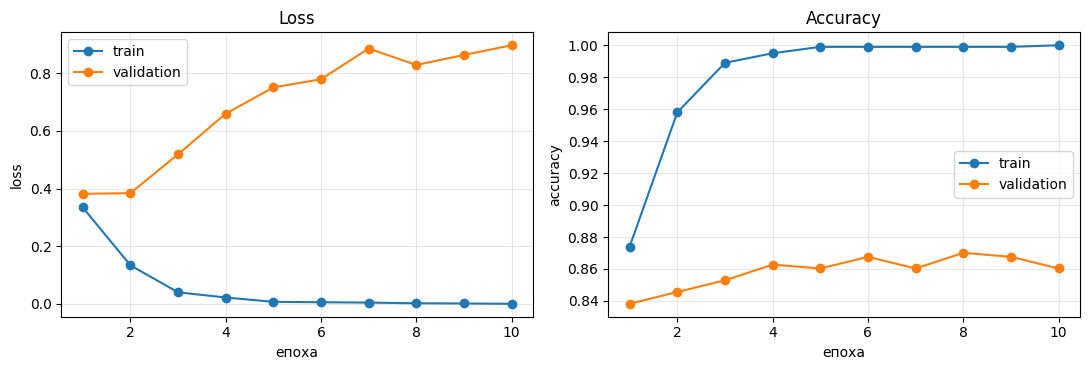

In [29]:
import matplotlib.pyplot as plt

merged = {}
for entry in long_trainer.state.log_history:
    if any(key.startswith("eval_") for key in entry):
        merged.setdefault(entry["step"], {"epoch": entry["epoch"]}).update({k: v for k, v in entry.items() if k.startswith("eval_")})
history = [h for h in merged.values() if "eval_validation_loss" in h and "eval_train_loss" in h]
assert history, "У журналі немає метрик після епох: чи виконано клітинку з long_trainer.train()?"
epochs_table = pd.DataFrame({
    "епоха": [round(h["epoch"]) for h in history],
    "train loss": [h["eval_train_loss"] for h in history],
    "val loss": [h["eval_validation_loss"] for h in history],
    "train accuracy": [h["eval_train_accuracy"] for h in history],
    "val accuracy": [h["eval_validation_accuracy"] for h in history],
    "val F1": [h["eval_validation_f1"] for h in history],
}).round(4)
print(epochs_table.to_string(index=False))

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
ax_loss.plot(epochs_table["епоха"], epochs_table["train loss"], marker="o", label="train")
ax_loss.plot(epochs_table["епоха"], epochs_table["val loss"], marker="o", label="validation")
ax_loss.set(xlabel="епоха", ylabel="loss", title="Loss")
ax_acc.plot(epochs_table["епоха"], epochs_table["train accuracy"], marker="o", label="train")
ax_acc.plot(epochs_table["епоха"], epochs_table["val accuracy"], marker="o", label="validation")
ax_acc.set(xlabel="епоха", ylabel="accuracy", title="Accuracy")
for ax in (ax_loss, ax_acc):
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
best_loss_row = epochs_table.loc[epochs_table["val loss"].idxmin()]
best_acc_row = epochs_table.loc[epochs_table["val accuracy"].idxmax()]
last = epochs_table.iloc[-1]

print(f"Найменший validation loss ({best_loss_row['val loss']:.3f}) — на епосі {int(best_loss_row['епоха'])}; "
      f"на епосі {int(last['епоха'])} він {last['val loss']:.3f} ({last['val loss'] / best_loss_row['val loss'] - 1:+.0%}).")
print(f"Найвища validation accuracy ({best_acc_row['val accuracy']:.3f}) — на епосі {int(best_acc_row['епоха'])}; "
      f"на епосі {int(last['епоха'])} вона {last['val accuracy']:.3f}.")
print(f"Train accuracy зросла до {last['train accuracy']:.3f}, train loss впав до {last['train loss']:.3f}.")
gap = last["train accuracy"] - last["val accuracy"]
if last["val loss"] > 1.1 * best_loss_row["val loss"] and gap > 0.05:
    print(f"Висновок: ознаки перенавчання — розрив між train і validation accuracy {gap:.1%}, validation loss зріс після мінімуму.")
elif last["val loss"] > 1.1 * best_loss_row["val loss"]:
    print("Висновок: validation loss зріс після мінімуму, хоча accuracy майже не змінилася — модель стала самовпевненішою.")
else:
    print("Висновок: помітного перенавчання на цих налаштуваннях не видно.")

Найменший validation loss (0.382) — на епосі 1; на епосі 10 він 0.896 (+135%).
Найвища validation accuracy (0.870) — на епосі 8; на епосі 10 вона 0.860.
Train accuracy зросла до 1.000, train loss впав до 0.001.
Висновок: ознаки перенавчання — розрив між train і validation accuracy 14.0%, validation loss зріс після мінімуму.


### Питання 10. Додайте ще 4 перевірки на власних даних в пункті 4 в 01_bert_head.

**Відповідь.** Чотири власні перевірки додано в секцію **4. Перевірка на власних прикладах** (клітинка «Додаткові перевірки на власних прикладах (питання 10)» одразу після початкових трьох пар). Вони перевіряють різні явища: інший порядок слів, ті самі слова з іншими ролями, заперечення й інше число.

**Результат запуску: правильно 1 із 4.**

| явище | еталон | P(парафраз) | вердикт |
|---|---|---|---|
| інший порядок слів, пасив | парафраз | 99,3% | ✓ |
| ті самі слова, ролі навпаки («dog bit man» / «man bit dog») | не парафраз | 98,1% | ✗ |
| заперечення («will recover» / «will not recover») | не парафраз | 99,2% | ✗ |
| інше число (500 / 5 000 працівників) | не парафраз | 97,4% | ✗ |

**Коментар.** Модель правильно розпізнала лише парафразу з іншою структурою речення, а три «пастки» — навпаки, рівно в тих випадках, де зміст змінився, а слова майже не змінились — назвала парафразами, до того ж **дуже впевнено** (97–99%). Тобто вона, схоже, орієнтується передусім на лексичний збіг двох речень, а не на зміст: у MRPC перекриття слів — сильна ознака парафрази, тож на тренуванні така евристика працює (86% на валідації), а на «змагальних» прикладах ламається. Те саме описано в роботі про датасет PAWS (Zhang et al., 2019): моделі на основі BERT без спеціальних тренувальних прикладів із перестановкою слів помиляються на парах із високим перекриттям, але різним змістом. Висновок: accuracy 86% на MRPC не означає, що модель розуміє заперечення, ролі чи числа; такі явища треба тестувати окремо й, за потреби, додавати відповідні приклади в навчання.